# Performance Plotting

Notebook for the current `performance-sionna-tcp` output layout. It reads the `tc*/throughput_results_*`, `snr_results_*`, `position_results_*`, and `computationtime_*` CSV files, and treats each configured result folder as one comparable server/raytracer setting.

Use `0.1` for a 0.1 ms coherence time if you set coherence times manually.

In [30]:
%matplotlib inline

from pathlib import Path
import importlib
import sys
import matplotlib.pyplot as plt

cwd = Path.cwd()
EXAMPLES_DIR = cwd if (cwd / "performance-sionna-tcp.cc").exists() else cwd / "examples"
if not EXAMPLES_DIR.exists():
    EXAMPLES_DIR = cwd
if str(EXAMPLES_DIR) not in sys.path:
    sys.path.insert(0, str(EXAMPLES_DIR))

import performance_plotting
importlib.reload(performance_plotting)

from performance_plotting import (
    default_apartment_server_datasets,
    load_performance_data,
    plot_metric_boxplot,
    plot_positions,
    plot_server_setting_comparison,
    plot_time_series,
    use_legacy_plot_style,
)
use_legacy_plot_style()

# Save switch. Keep this False while exploring; set True to write figures to FIGURE_DIR.
SAVE_PLOTS = False
FIGURE_DIR = EXAMPLES_DIR / "plots"

# Layer1 folder names use tc1/tc10/tc100/tc1000 for 0.1/1/10/100 ms.
COHERENCE_TIME_SCALE = 0.1

# None means auto-detect everything available. Example: [0.1, 1, 10, 100]
COHERENCE_TIMES = None
SEEDS = None

THROUGHPUT_INTERVAL_MS = 100
DROP_ZERO_THROUGHPUT = True
SINGLE_DATASET = "Current"
SINGLE_SEED = 1
SINGLE_COHERENCE_MS = 0.1
SNR_STA_NODE_IDS = None
AP_POSITION = (-1.0, 0.5)

CURRENT_DATASETS = {
    "Current": EXAMPLES_DIR / "results_Equidistand" / "Layer1Speed",
}

SERVER_DATASETS = default_apartment_server_datasets(EXAMPLES_DIR / "results_Apartment")
SERVER_DATASETS

{'Full': WindowsPath('C:/Users/zabel/Documents/Uni/tkn/ns3sionna_jan/examples/results_Apartment/results_FullNew'),
 'No diffraction': WindowsPath('C:/Users/zabel/Documents/Uni/tkn/ns3sionna_jan/examples/results_Apartment/results_noDiffracNew'),
 'No diffuse scattering': WindowsPath('C:/Users/zabel/Documents/Uni/tkn/ns3sionna_jan/examples/results_Apartment/results_noDiffuseNew'),
 'No reflection': WindowsPath('C:/Users/zabel/Documents/Uni/tkn/ns3sionna_jan/examples/results_Apartment/results_noReflecNew'),
 'No refraction': WindowsPath('C:/Users/zabel/Documents/Uni/tkn/ns3sionna_jan/examples/results_Apartment/results_noRefracNew'),
 'Three bounces': WindowsPath('C:/Users/zabel/Documents/Uni/tkn/ns3sionna_jan/examples/results_Apartment/results_threeBounce'),
 'Four bounces': WindowsPath('C:/Users/zabel/Documents/Uni/tkn/ns3sionna_jan/examples/results_Apartment/results_fourBounce')}

## Load Data

In [31]:
current_data = load_performance_data(
    CURRENT_DATASETS,
    coherence_times=COHERENCE_TIMES,
    seeds=SEEDS,
    coherence_time_scale=COHERENCE_TIME_SCALE,
)
current_data.summary()

,table,rows,datasets,coherence_times_ms,seeds
0,throughput,86944,1,"0.1 ms, 1 ms, 10 ms, 100 ms","1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12..."
1,snr,739684,1,"0.1 ms, 1 ms, 10 ms, 100 ms","1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12..."
2,positions,739684,1,"0.1 ms, 1 ms, 10 ms, 100 ms","1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12..."
3,computation,88,1,"0.1 ms, 1 ms, 10 ms, 100 ms","1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12..."


In [32]:
server_data = load_performance_data(
    SERVER_DATASETS,
    coherence_times=COHERENCE_TIMES,
    seeds=SEEDS,
    coherence_time_scale=COHERENCE_TIME_SCALE,
)
server_data.summary()

,table,rows,datasets,coherence_times_ms,seeds
0,throughput,63232,7,"0.1 ms, 1 ms, 10 ms, 100 ms",1-10
1,snr,2948860,7,"0.1 ms, 1 ms, 10 ms, 100 ms",1-10
2,positions,3301114,7,"0.1 ms, 1 ms, 10 ms, 100 ms",1-10
3,computation,82,7,"0.1 ms, 1 ms, 10 ms, 100 ms",1-10


## Coherence Sweeps

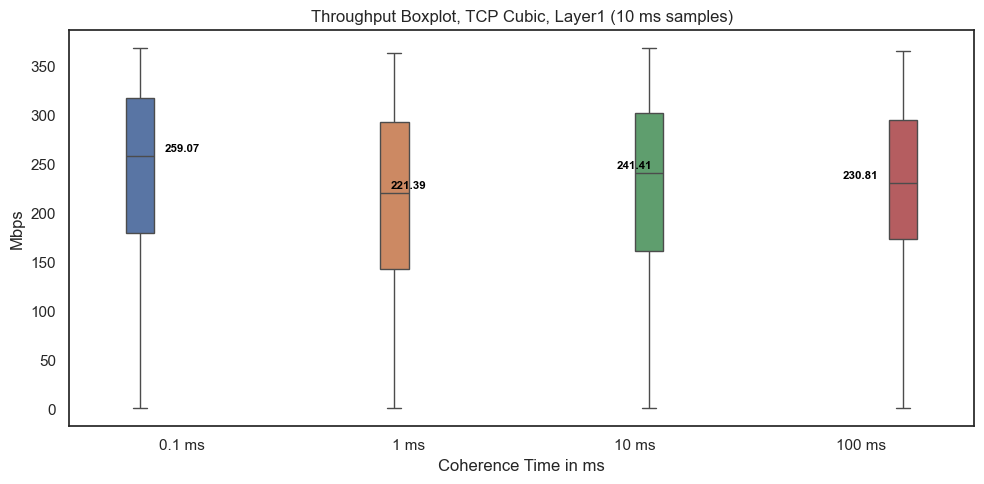

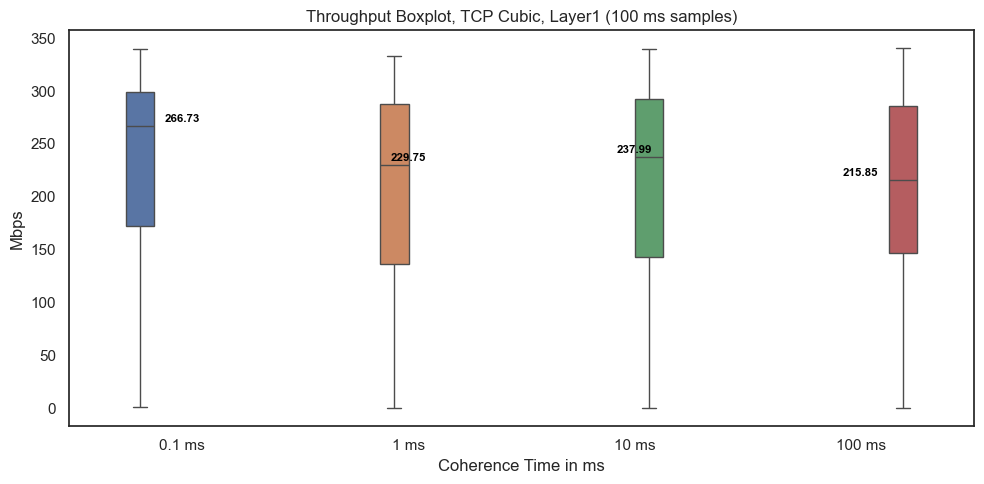

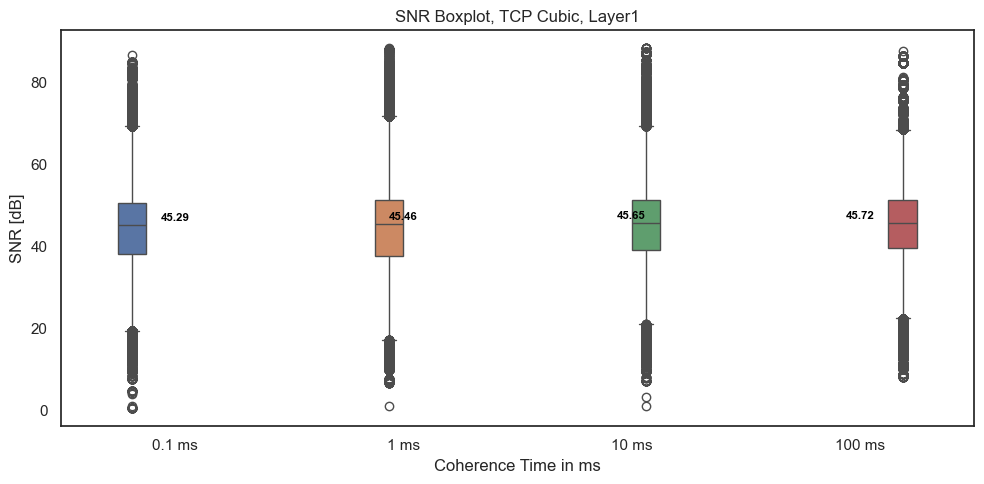

In [33]:
for interval_ms in [10, 100]:
    try:
        plot_metric_boxplot(
            current_data,
            metric="throughput",
            interval_ms=interval_ms,
            drop_zero_throughput=DROP_ZERO_THROUGHPUT,
            by_run=False,
            title=f"Throughput Boxplot, TCP Cubic, Layer1 ({interval_ms} ms samples)",
            save=SAVE_PLOTS,
            output_dir=FIGURE_DIR,
            filename=f"throughput_boxplot_layer1_{interval_ms}ms.png",
        )
        plt.show()
    except ValueError as exc:
        print(f"[skip] Throughput boxplot ({interval_ms} ms): {exc}")

try:
    plot_metric_boxplot(
        current_data,
        metric="snr",
        interval_ms=THROUGHPUT_INTERVAL_MS,
        drop_zero_throughput=DROP_ZERO_THROUGHPUT,
        by_run=False,
        sta_node_ids=SNR_STA_NODE_IDS,
        title="SNR Boxplot, TCP Cubic, Layer1",
        save=SAVE_PLOTS,
        output_dir=FIGURE_DIR,
        filename="snr_boxplot_layer1.png",
    )
    plt.show()
except ValueError as exc:
    print(f"[skip] SNR boxplot: {exc}")

## Single Seed Time Series

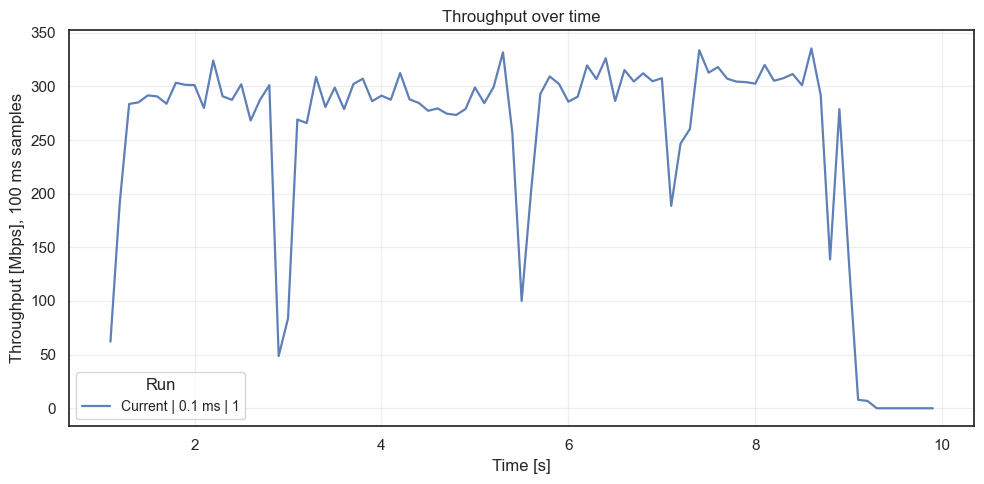

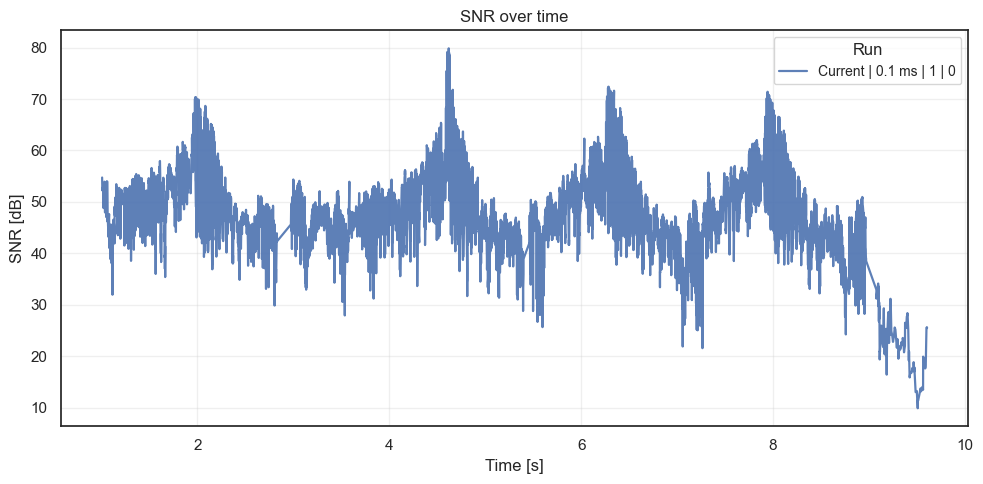

In [34]:
try:
    plot_time_series(
        current_data,
        metric="throughput",
        dataset=SINGLE_DATASET,
        coherence_ms=SINGLE_COHERENCE_MS,
        seed=SINGLE_SEED,
        interval_ms=THROUGHPUT_INTERVAL_MS,
        save=SAVE_PLOTS,
        output_dir=FIGURE_DIR,
        filename=f"throughput_time_seed{SINGLE_SEED}_tc{SINGLE_COHERENCE_MS}.png",
    )
    plt.show()
except ValueError as exc:
    print(f"[skip] Throughput time series: {exc}")

try:
    plot_time_series(
        current_data,
        metric="snr",
        dataset=SINGLE_DATASET,
        coherence_ms=SINGLE_COHERENCE_MS,
        seed=SINGLE_SEED,
        sta_node_ids=SNR_STA_NODE_IDS,
        save=SAVE_PLOTS,
        output_dir=FIGURE_DIR,
        filename=f"snr_time_seed{SINGLE_SEED}_tc{SINGLE_COHERENCE_MS}.png",
    )
    plt.show()
except ValueError as exc:
    print(f"[skip] SNR time series: {exc}")

## Positions

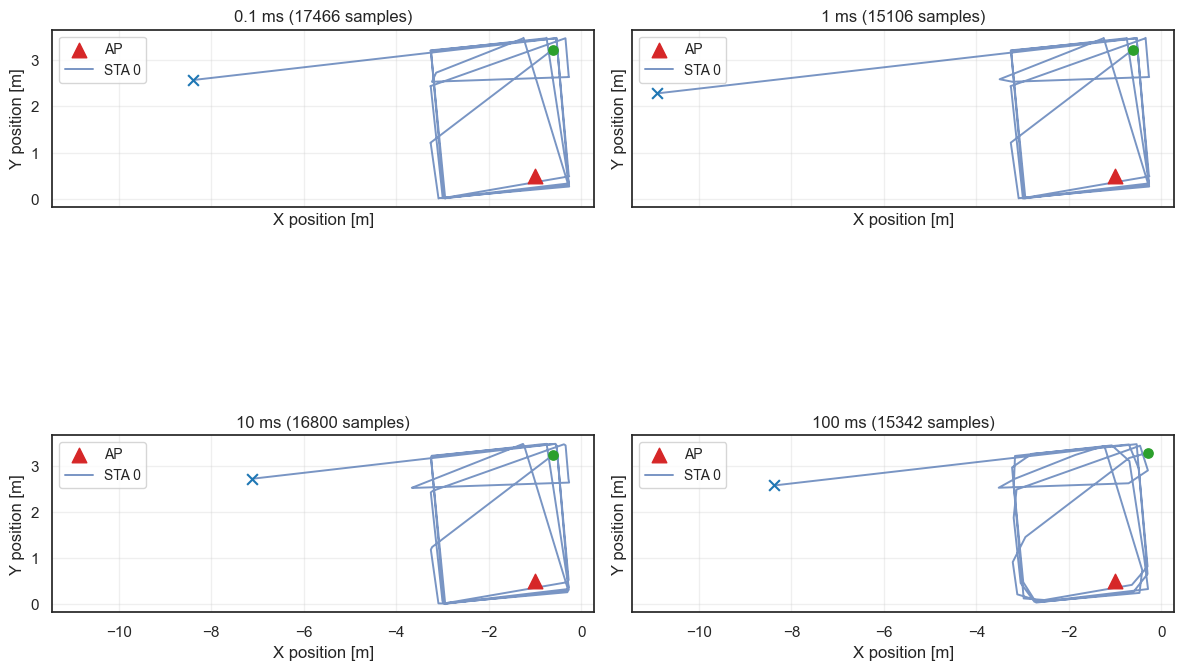

In [35]:
try:
    plot_positions(
        current_data,
        dataset=SINGLE_DATASET,
        coherence_times=COHERENCE_TIMES, #  or [SINGLE_COHERENCE_MS]
        seed=1,
        sta_node_ids=SNR_STA_NODE_IDS,
        ap_position=AP_POSITION,
        save=SAVE_PLOTS,
        output_dir=FIGURE_DIR,
        filename=f"positions_seed{SINGLE_SEED}.png",
    )
    plt.show()
except ValueError as exc:
    print(f"[skip] Position plot: {exc}")

## Boxplots

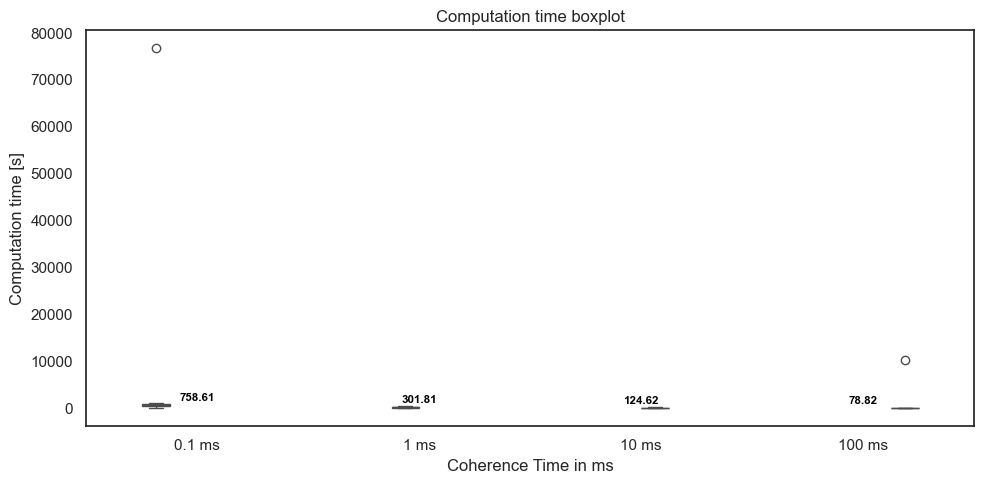

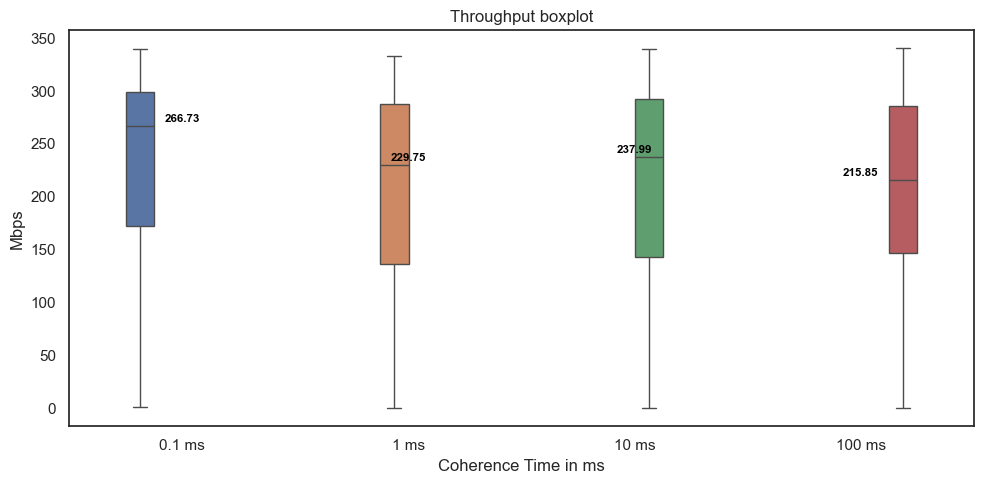

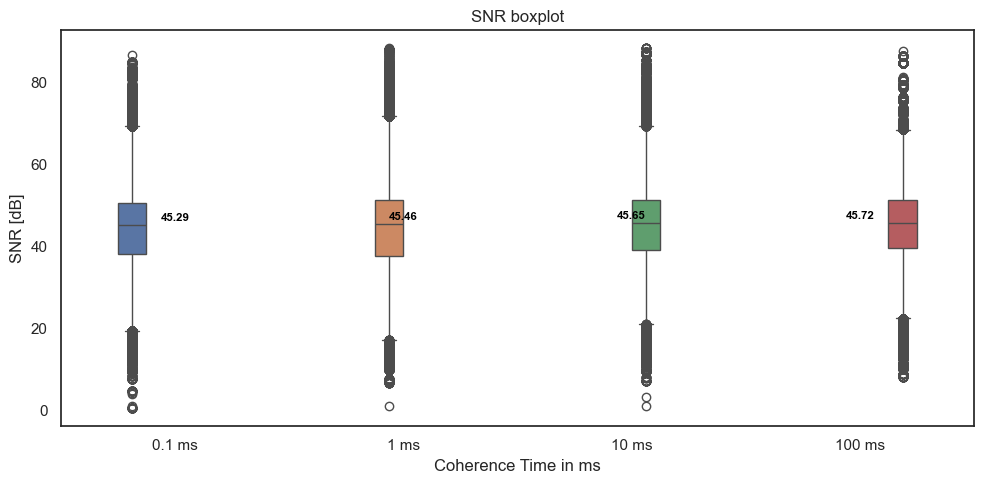

In [36]:
boxplot_data = current_data

for metric in ["computation_time", "throughput", "snr"]:
    try:
        plot_metric_boxplot(
            boxplot_data,
            metric=metric,
            interval_ms=THROUGHPUT_INTERVAL_MS,
            drop_zero_throughput=DROP_ZERO_THROUGHPUT,
            by_run=(metric == "computation_time"),
            sta_node_ids=SNR_STA_NODE_IDS,
            save=SAVE_PLOTS,
            output_dir=FIGURE_DIR,
            filename=f"{metric}_boxplot.png",
        )
        plt.show()
    except ValueError as exc:
        print(f"[skip] {metric} boxplot: {exc}")

## Server/Raytracer Settings

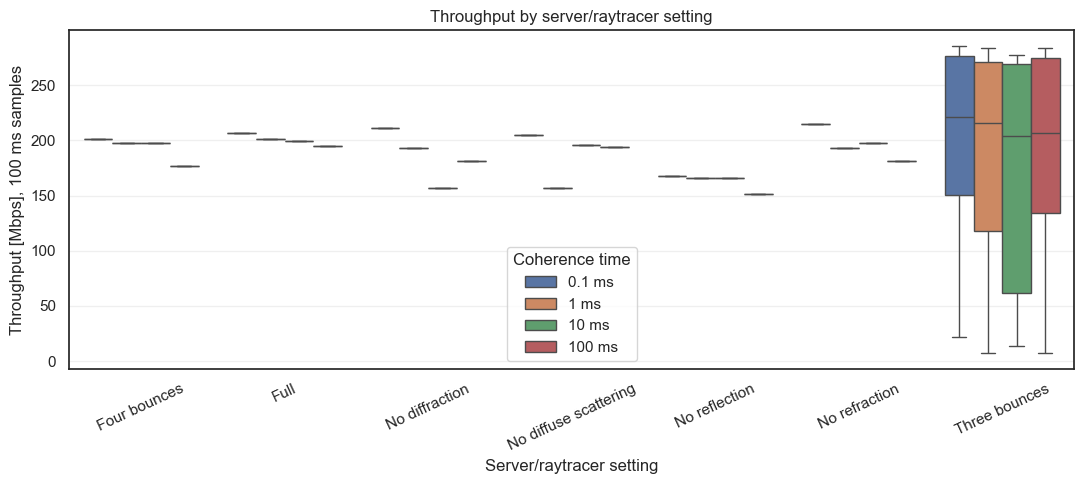

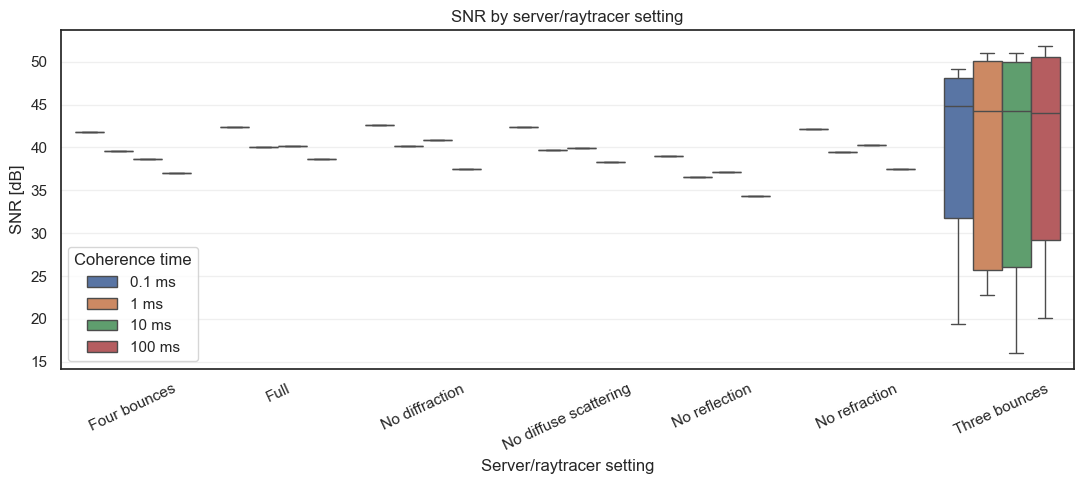

In [37]:
for metric in ["throughput", "snr"]:
    try:
        plot_server_setting_comparison(
            server_data,
            metric=metric,
            interval_ms=THROUGHPUT_INTERVAL_MS,
            drop_zero_throughput=DROP_ZERO_THROUGHPUT,
            coherence_times=COHERENCE_TIMES,
            sta_node_ids=SNR_STA_NODE_IDS,
            save=SAVE_PLOTS,
            output_dir=FIGURE_DIR,
            filename=f"{metric}_server_settings.png",
        )
        plt.show()
    except ValueError as exc:
        print(f"[skip] {metric} server setting comparison: {exc}")

## Add A Comparison

In [ ]:
def quick_compare(label_to_path, metric="throughput", coherence_times=None, seeds=None, interval_ms=THROUGHPUT_INTERVAL_MS, coherence_time_scale=COHERENCE_TIME_SCALE):
    """Load any result folders and draw the two comparison plots used most often."""
    comparison = load_performance_data(
        label_to_path,
        coherence_times=coherence_times,
        seeds=seeds,
        coherence_time_scale=coherence_time_scale,
    )
    display(comparison.summary())

    plot_metric_boxplot(
        comparison,
        metric=metric,
        interval_ms=interval_ms,
        drop_zero_throughput=DROP_ZERO_THROUGHPUT,
        by_run=False,
        save=SAVE_PLOTS,
        output_dir=FIGURE_DIR,
        filename=f"{metric}_quick_boxplot.png",
    )
    plt.show()

    plot_server_setting_comparison(
        comparison,
        metric=metric,
        interval_ms=interval_ms,
        drop_zero_throughput=DROP_ZERO_THROUGHPUT,
        coherence_times=coherence_times,
        save=SAVE_PLOTS,
        output_dir=FIGURE_DIR,
        filename=f"{metric}_quick_settings.png",
    )
    plt.show()
    return comparison

# Example:
# my_data = quick_compare({
#     "Full": EXAMPLES_DIR / "results_Apartment" / "results_FullNew",
#     "No reflection": EXAMPLES_DIR / "results_Apartment" / "results_noReflecNew",
# }, metric="snr", coherence_times=[0.1, 1, 10], seeds=range(1, 6))